In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
#import time

np.set_printoptions(threshold=sys.maxsize)

In [7]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)


#YCT = np.linspace(-200*AY,(M+200)*AY,101)

print('X co-ordinate of charge trap =', XCT )

ZCT = 50
ZIM = 64

#Ep_cu = np.load('cubic_E_vs_yct_Zdiff_{}_wider_yct_width_{}nm_refined.npy'.format(ZIM-ZCT ,LY))
Ep_cu = np.load('cubic_E_vs_yct_image_chrg_model_full_4_layers_full_pts_Vfinal_ax_ay_10_10.npy')

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418
X co-ordinate of charge trap = 4150.0


In [8]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)


MU_SM = OMEGA/2 + 0.8
MU_SC = OMEGA/2 + 0.8


print('mu = ', MU_SM)

XCT = (NSC+NSM/2)*AX

# Define the boundary points
a = -100*AY
b = 0
c = M*AY
d = (M+100)*AY

# Define the number of points between each segment
n_ab = 50  # number of points between a and b
n_bc = 101  # number of points between b and c (more points)
n_cd = 50  # number of points between c and d

# Create linearly spaced points between each pair
y_ab = np.linspace(a, b, n_ab, endpoint=False)
y_bc = np.linspace(b, c, n_bc, endpoint=False)
y_cd = np.linspace(c, d, n_cd, endpoint=True)

# Concatenate all points
YCT = np.concatenate((y_ab, y_bc, y_cd))

#print(YCT)

#YCT = np.linspace(-200*AY,(M+200)*AY,101)
ZCT = 50
ZIM = 64

print('X co-ordinate of charge trap =', XCT )

#Ep_li = np.load('linear_E_vs_yct_Zdiff_{}_wider_yct_width_{}nm_refined.npy'.format(ZIM-ZCT ,LY))
Ep_li = np.load('linear_E_vs_yct_image_chrg_model_full_4_layers_full_pts_Vfinal_ax_ay_10_10.npy')

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418
X co-ordinate of charge trap = 4150.0


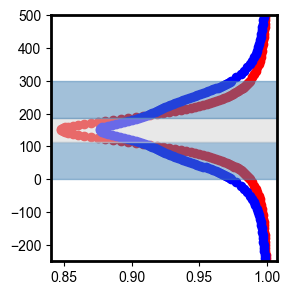

In [9]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=10)

f = plt.figure(figsize=(3, 3))

ax = plt.gca()

cubic_spin_split = Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)

Ep_wct_cu = (Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2])/max_spin_split


linear_spin_split = Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct_li = (Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2])/max_spin_split

#XTICKS = [0, 300]

#X_TICK_LABELS = [r'$-150$', r'$150$']

plt.scatter(Ep_wct_cu, YCT,  color='red')
plt.scatter(Ep_wct_li, YCT, color='blue')
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

# Color the horizontal region from y=0 to y=300
#ax.axhspan(0, 300, color='lightgrey', alpha=0.5)


# Define colors using RGB values
lightgray = (211/255, 211/255, 211/255)  # Light gray
midblue = (70/255, 130/255, 180/255)  # Medium blue

ax.axhspan(0, 112.5, color=midblue, alpha=0.5)

ax.axhspan(112.5, 187.5, color=lightgray, alpha=0.5)

ax.axhspan(187.5, 300, color=midblue, alpha=0.5)

# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, color='black', linestyle='dotted', lw=3)
#plt.axvline(x=M*AY, color='black', linestyle='dotted', lw=3)

#plt.xticks(XTICKS, X_TICK_LABELS)

plt.tight_layout()

plt.ylim(ymin=-250, ymax=500)

# Save the figure
plt.savefig('Es_vs_chargetrap_cu_li_rotated.png', dpi=300, bbox_inches='tight')  # Use 300 dpi for high-quality images

#plt.xlabel(r'coordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
#plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)



In [10]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
})

In [11]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
})

C:\Users\Vivrekar\AppData\Local\Temp\5\ipykernel_24648\732276919.py:96: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


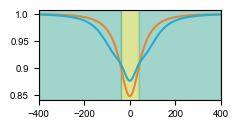

In [18]:
# Set the font family to Arial
#plt.rcParams['font.family'] = 'Arial'

#plt.rc('font', size=40)
#plt.rc('font', size=20)



#f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(8, 4))
f = plt.figure(figsize=(2.354, 1.177))

ax = plt.gca()

cubic_spin_split = Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)

Ep_wct_cu = (Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2])/max_spin_split


linear_spin_split = Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct_li = (Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2])/max_spin_split

#XTICKS = [0, 300]

#X_TICK_LABELS = [r'$-150$', r'$150$']


# Color the horizontal region from y=0 to y=300
#ax.axhspan(0, 300, color='lightgrey', alpha=0.5)


# Define colors using RGB values
lightgray = (211/255, 211/255, 211/255)  # Light gray
midblue = (70/255, 130/255, 180/255)  # Medium blue
pear = (187/255, 204/255, 51/255)
teal = (68/255, 170/255, 153/255)



ax.axvspan(-75/2, 75/2, color=pear, alpha=0.5)

ax.axvspan(-400, -75/2-1.5 , color=teal, alpha=0.5)

ax.axvspan(75/2+1.5, 400, color=teal, alpha=0.5)

colors = ["#26abd3","#e48635"]
#colors = ["#33a8cc","#cf803a"]

#plt.scatter(YCT -M/2*AY, Ep_wct_cu, color='red')
#plt.scatter(YCT - M/2*AY, Ep_wct_li, color='blue')
plt.plot(YCT -M/2*AY, Ep_wct_cu, color=colors[1], lw=1.5)
plt.plot(YCT - M/2*AY, Ep_wct_li, color=colors[0], lw=1.5)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.axvline(x=0)

# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)


# Increase tick mark length
#plt.tick_params(axis='both', which='major', length=10, width=3)  # Major ticks
#plt.tick_params(axis='both', which='minor', length=10, width=3)   # Minor ticks

# Increase tick label padding
#ax.tick_params(axis='x', pad=8)  # Increase padding for X-axis tick labels
#ax.tick_params(axis='y', pad=15)  # Increase padding for Y-axis tick labels


# Customize the spines' appearance (optional)
#for spine in ax.spines.values():
#    spine.set_linewidth(2)  # Set the thickness of the box
#    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, color='black', linestyle='dotted', lw=3)
#plt.axvline(x=M*AY, color='black', linestyle='dotted', lw=3)

YTICKS = [0.85, 0.90, 0.95, 1.00]

Y_TICK_LABELS = [0.85, 0.90, 0.95, 1.00]

plt.yticks(YTICKS, Y_TICK_LABELS)

plt.tight_layout()

plt.xlim(xmin=-400, xmax=400)

# Save the figure
plt.savefig('Es_vs_chargetrap_cu_li_4_layers.png', dpi=300, bbox_inches='tight')  # Use 300 dpi for high-quality images

#plt.xlabel(r'coordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
#plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)


Text(54.44444444444444, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

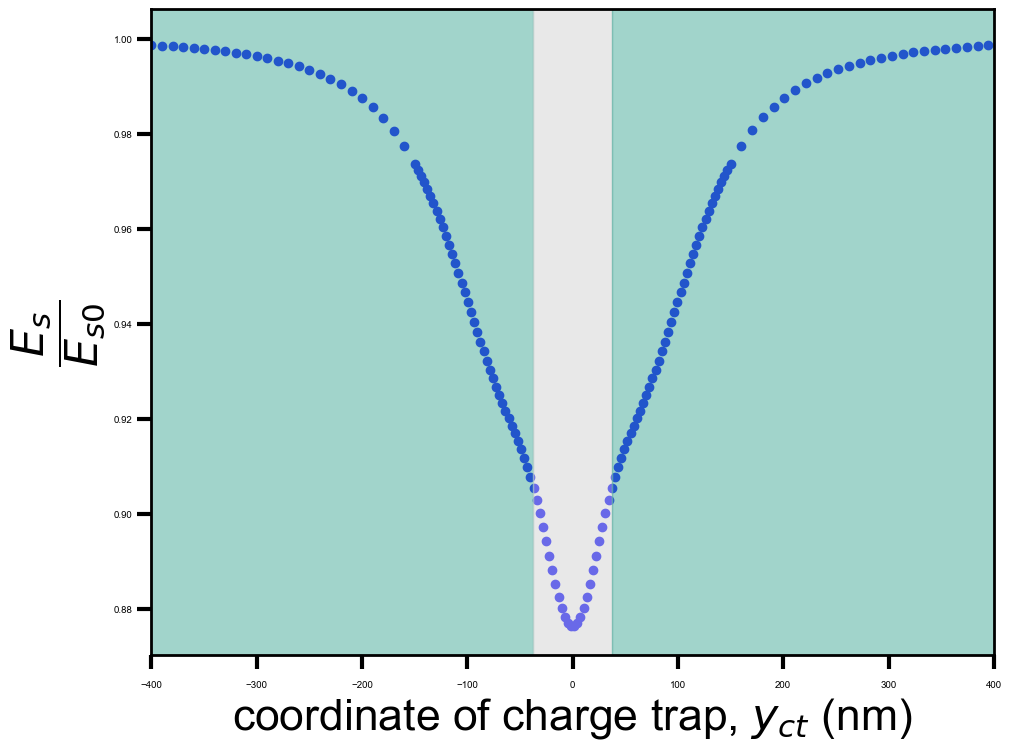

In [19]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=40)

f = plt.figure(figsize=(10, 8))

ax = plt.gca()

cubic_spin_split = Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)

Ep_wct_cu = (Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2])/max_spin_split


linear_spin_split = Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct_li = (Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2])/max_spin_split

#XTICKS = [0, 300]

#X_TICK_LABELS = [r'$-150$', r'$150$']

#plt.scatter(YCT -M/2*AY, Ep_wct_cu, color='red')
plt.scatter(YCT - M/2*AY, Ep_wct_li, color='blue')
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

# Color the horizontal region from y=0 to y=300
#ax.axhspan(0, 300, color='lightgrey', alpha=0.5)


# Define colors using RGB values
lightgray = (211/255, 211/255, 211/255)  # Light gray
midblue = (70/255, 130/255, 180/255)  # Medium blue
pear = (187/255, 204/255, 51/255)
teal = (68/255, 170/255, 153/255)

ax.axvspan(-400, -75/2, color=teal, alpha=0.5)

ax.axvspan(-75/2, 75/2, color=lightgray, alpha=0.5)

ax.axvspan(75/2, 400, color=teal, alpha=0.5)

# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)


# Increase tick mark length
plt.tick_params(axis='both', which='major', length=10, width=3)  # Major ticks
plt.tick_params(axis='both', which='minor', length=10, width=3)   # Minor ticks

# Increase tick label padding
ax.tick_params(axis='x', pad=8)  # Increase padding for X-axis tick labels
#ax.tick_params(axis='y', pad=15)  # Increase padding for Y-axis tick labels


# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, color='black', linestyle='dotted', lw=3)
#plt.axvline(x=M*AY, color='black', linestyle='dotted', lw=3)

#plt.xticks(XTICKS, X_TICK_LABELS)

plt.tight_layout()

plt.xlim(xmin=-400, xmax=400)

# Save the figure
plt.savefig('Es_vs_chargetrap_cu_li_4_layers_big_fig.png', dpi=300, bbox_inches='tight')  # Use 300 dpi for high-quality images

plt.xlabel(r'coordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)


Text(54.44444444444444, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

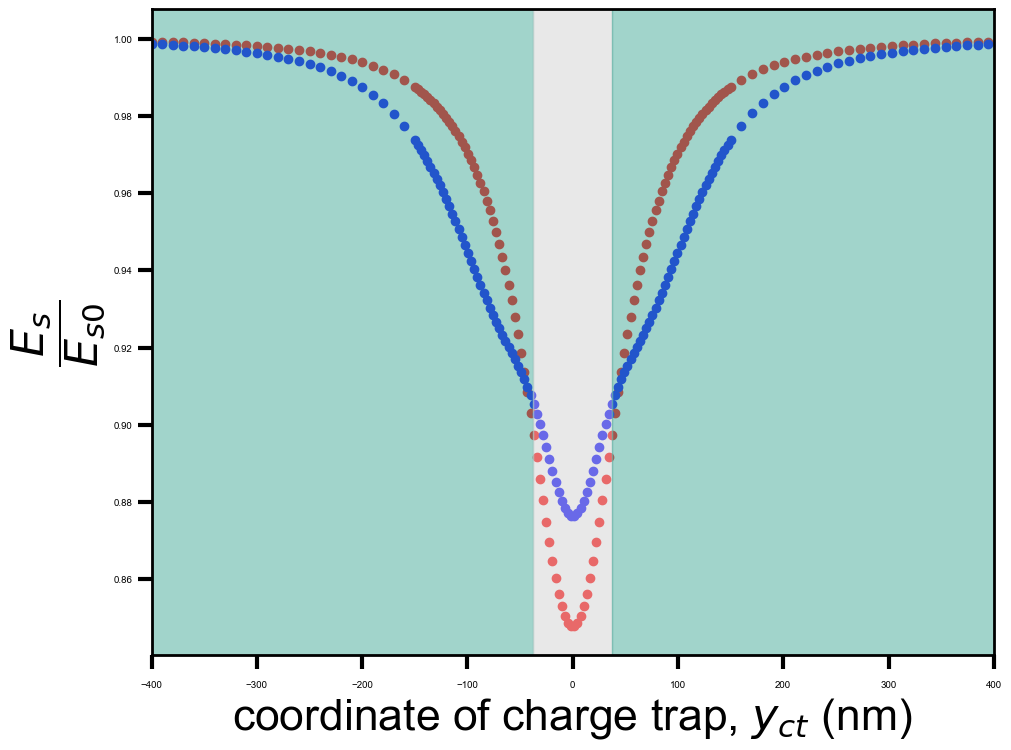

In [20]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=40)

f = plt.figure(figsize=(10, 8))

ax = plt.gca()

cubic_spin_split = Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)

Ep_wct_cu = (Ep_cu[:, K_NUM//2+1]-Ep_cu[:, K_NUM//2])/max_spin_split


linear_spin_split = Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2] 

min_spin_split = np.min(linear_spin_split)

max_spin_split = np.max(linear_spin_split)

Ep_wct_li = (Ep_li[:, K_NUM//2+1]-Ep_li[:, K_NUM//2])/max_spin_split

#XTICKS = [0, 300]

#X_TICK_LABELS = [r'$-150$', r'$150$']

plt.scatter(YCT -M/2*AY, Ep_wct_cu, color='red')
plt.scatter(YCT - M/2*AY, Ep_wct_li, color='blue')
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

# Color the horizontal region from y=0 to y=300
#ax.axhspan(0, 300, color='lightgrey', alpha=0.5)


# Define colors using RGB values
lightgray = (211/255, 211/255, 211/255)  # Light gray
midblue = (70/255, 130/255, 180/255)  # Medium blue
pear = (187/255, 204/255, 51/255)
teal = (68/255, 170/255, 153/255)

ax.axvspan(-400, -75/2, color=teal, alpha=0.5)

ax.axvspan(-75/2, 75/2, color=lightgray, alpha=0.5)

ax.axvspan(75/2, 400, color=teal, alpha=0.5)

# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)


# Increase tick mark length
plt.tick_params(axis='both', which='major', length=10, width=3)  # Major ticks
plt.tick_params(axis='both', which='minor', length=10, width=3)   # Minor ticks

# Increase tick label padding
ax.tick_params(axis='x', pad=8)  # Increase padding for X-axis tick labels
#ax.tick_params(axis='y', pad=15)  # Increase padding for Y-axis tick labels


# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, color='black', linestyle='dotted', lw=3)
#plt.axvline(x=M*AY, color='black', linestyle='dotted', lw=3)

#plt.xticks(XTICKS, X_TICK_LABELS)

plt.tight_layout()

plt.xlim(xmin=-400, xmax=400)

# Save the figure
plt.savefig('Es_vs_chargetrap_cu_li_earlier_fig_4_layers.png', dpi=300, bbox_inches='tight')  # Use 300 dpi for high-quality images

plt.xlabel(r'coordinate of charge trap, $y_{ct}$ (nm)', fontsize=32)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=32)


Text(54.44444444444444, 0.5, '$\\dfrac{E_s}{E_{s0}}$')

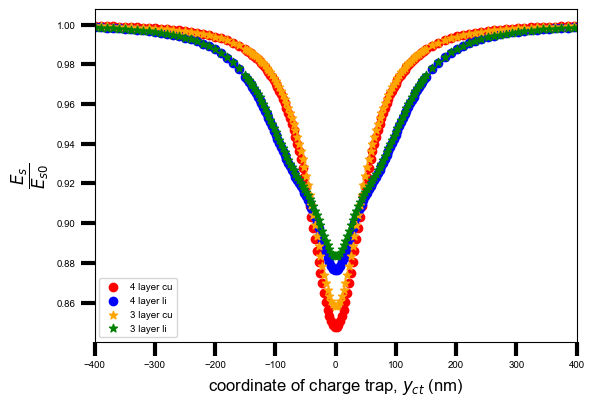

In [25]:
Ep_li2 = np.load('linear_E_vs_yct_image_chrg_model_full.npy')
Ep_cu2 = np.load('cubic_E_vs_yct_image_chrg_model_full.npy')

cubic_spin_split2 = Ep_cu2[:, K_NUM//2+1]-Ep_cu2[:, K_NUM//2] 

min_spin_split2 = np.min(cubic_spin_split2)

max_spin_split2 = np.max(cubic_spin_split2)

Ep_wct_cu2 = (Ep_cu2[:, K_NUM//2+1]-Ep_cu2[:, K_NUM//2])/max_spin_split2


linear_spin_split2 = Ep_li2[:, K_NUM//2+1]-Ep_li2[:, K_NUM//2] 

min_spin_split2 = np.min(linear_spin_split2)

max_spin_split2 = np.max(linear_spin_split2)

Ep_wct_li2 = (Ep_li2[:, K_NUM//2+1]-Ep_li2[:, K_NUM//2])/max_spin_split2


#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

# Color the horizontal region from y=0 to y=300
#ax.axhspan(0, 300, color='lightgrey', alpha=0.5)


# Define colors using RGB values
lightgray = (211/255, 211/255, 211/255)  # Light gray
midblue = (70/255, 130/255, 180/255)  # Medium blue
pear = (187/255, 204/255, 51/255)
teal = (68/255, 170/255, 153/255)

ax.axvspan(-400, -75/2, color=teal, alpha=0.5)

ax.axvspan(-75/2, 75/2, color=lightgray, alpha=0.5)

ax.axvspan(75/2, 400, color=teal, alpha=0.5)

plt.scatter(YCT -M/2*AY, Ep_wct_cu, color='red', label='4 layer cu')
plt.scatter(YCT - M/2*AY, Ep_wct_li, color='blue', label='4 layer li')
plt.scatter(YCT -M/2*AY, Ep_wct_cu2, color='orange', marker="*", label='3 layer cu')
plt.scatter(YCT - M/2*AY, Ep_wct_li2, color='green', marker="*", label='3 layer li')

# Add a box around the plot
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)


# Increase tick mark length
plt.tick_params(axis='both', which='major', length=10, width=3)  # Major ticks
plt.tick_params(axis='both', which='minor', length=10, width=3)   # Minor ticks

# Increase tick label padding
ax.tick_params(axis='x', pad=8)  # Increase padding for X-axis tick labels
#ax.tick_params(axis='y', pad=15)  # Increase padding for Y-axis tick labels


# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(2)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

#plt.axvline(x=0, color='black', linestyle='dotted', lw=3)
#plt.axvline(x=M*AY, color='black', linestyle='dotted', lw=3)

#plt.xticks(XTICKS, X_TICK_LABELS)

plt.tight_layout()

plt.xlim(xmin=-400, xmax=400)

plt.legend()

# Save the figure
plt.savefig('Es_vs_chargetrap_cu_li_3_layers_vs_4_layers.png', dpi=300, bbox_inches='tight')  # Use 300 dpi for high-quality images

plt.xlabel(r'coordinate of charge trap, $y_{ct}$ (nm)', fontsize=12)
plt.ylabel(r'$\dfrac{E_s}{E_{s0}}$', fontsize=12)